In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')

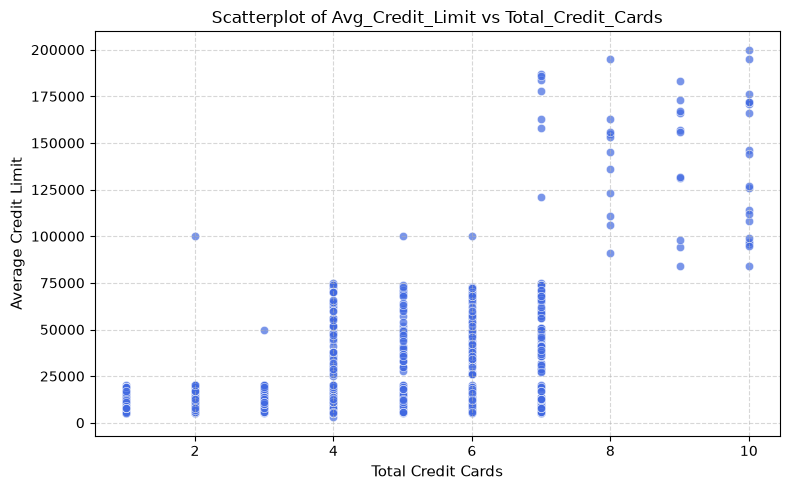

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Total_Credit_Cards',
    y='Avg_Credit_Limit',
    color='royalblue',
    alpha=0.7,
)
plt.title('Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards', fontsize=12)
plt.xlabel('Total Credit Cards', fontsize=11)
plt.ylabel('Average Credit Limit', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made',
]
X = df[features]

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
sse = []
K = range(1, 11)

In [ ]:
for k in K:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  sse.append(kmeans.inertia_)

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

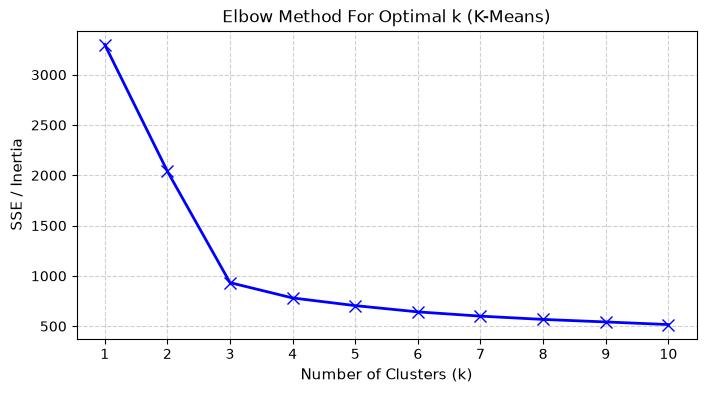

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('SSE / Inertia', fontsize=11)
plt.title('Elbow Method For Optimal k (K-Means)', fontsize=12)
plt.xticks(K)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


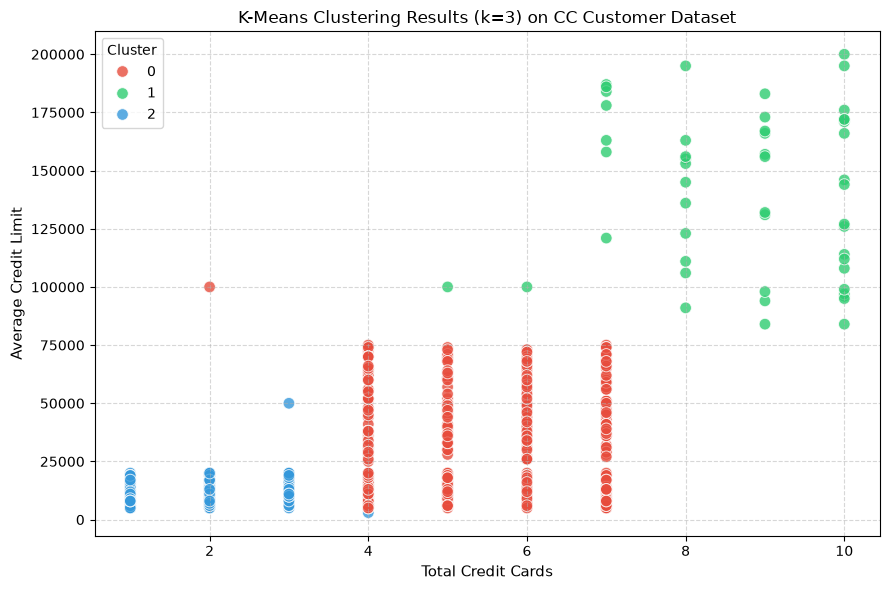

In [ ]:
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_opt.fit_predict(X_scaled)

# Plot Clusters
plt.figure(figsize=(9, 6))
palette = ['#e74c3c', '#2ecc71', '#3498db']
sns.scatterplot(
    data=df,
    x='Total_Credit_Cards',
    y='Avg_Credit_Limit',
    hue='KMeans_Cluster',
    palette=palette,
    s=70,
    alpha=0.8,
)

plt.title(
    'K-Means Clustering Results (k=3) on CC Customer Dataset', fontsize=12
)
plt.xlabel('Total Credit Cards', fontsize=11)
plt.ylabel('Average Credit Limit', fontsize=11)
plt.legend(title='Cluster', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [ ]:
k_neighbors = 5  # min_samples parameter
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

In [ ]:
k_distances = np.sort(distances[:, k_neighbors - 1])

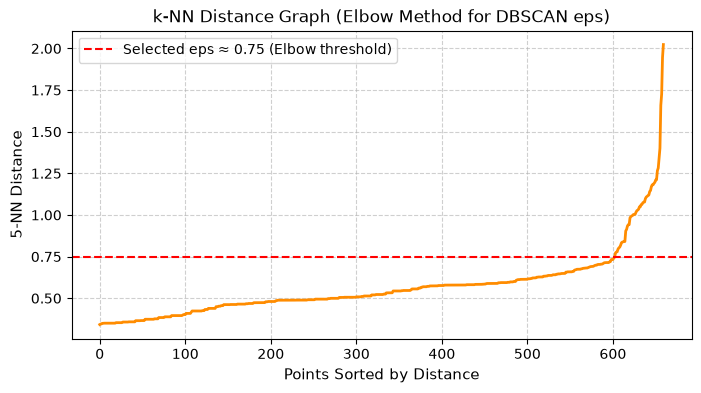

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(k_distances, color='darkorange', linewidth=2)
plt.axhline(
    y=0.75,
    color='red',
    linestyle='--',
    label='Selected eps ≈ 0.75 (Elbow threshold)',
)
plt.xlabel('Points Sorted by Distance', fontsize=11)
plt.ylabel(f'{k_neighbors}-NN Distance', fontsize=11)
plt.title('k-NN Distance Graph (Elbow Method for DBSCAN eps)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
dbscan = DBSCAN(eps=0.75, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Summary clusters formed
n_clusters = len(set(df['DBSCAN_Cluster'])) - (
    1 if -1 in df['DBSCAN_Cluster'].values else 0
)
n_noise = (df['DBSCAN_Cluster'] == -1).sum()
print(f'Number of clusters formed: {n_clusters}')
print(f'Number of noise points: {n_noise}')

Number of clusters formed: 2
Number of noise points: 47


In [ ]:
from sklearn.metrics import davies_bouldin_score, silhouette_score

labels = df['DBSCAN_Cluster']

sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print(f'DBSCAN Silhouette Score: {sil_score:.4f}')
print(f'DBSCAN Davies-Bouldin Index (DBI): {dbi_score:.4f}')

DBSCAN Silhouette Score: 0.4720
DBSCAN Davies-Bouldin Index (DBI): 2.0047
